## NB08 — Treinamento e Avaliação de Modelos

**Entrada:** `data/load/dataset_ml_model.csv` — 76.218 linhas × 25 colunas (gerado pelo NB07)

**Objetivo:** Treinar e avaliar o modelo de detecção de anomalias **Isolation Forest, LOF e One Class SVM** sobre o
dataset de propostas de licitações de Pernambuco (2020–2024).

In [29]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

os.makedirs('data/load', exist_ok=True)
print('Setup OK')

Setup OK


In [30]:
df = pd.read_csv('data/load/dataset_ml_model.csv')

print(f'Shape: {df.shape}')
print(f'\nColunas ({len(df.columns)}):')
print(list(df.columns))
print('\nTipos de dados:')
print(df.dtypes)
df.head(3)

Shape: (76218, 25)

Colunas (25):
['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp', 'numeroItem', 'cnpj_forn_norm', 'desvio_item_estimado', 'n_propostas_item', 'fornecedor_unico', 'ano', 'mes', 'trimestre', 'dia_semana', 'dias_para_eleicao', 'ano_eleitoral', 'pre_eleitoral_180d', 'fornecedor_fora_pe', 'tipo_fornecedor', 'idade_empresa_anos', 'empresa_nova', 'opcao_pelo_mei', 'opcao_pelo_simples', 'modalidadeNome', 'porte', 'cnae_fiscal', 'descricao_situacao_cadastral']

Tipos de dados:
orgaoEntidadeCnpj                 int64
anoCompraPncp                     int64
sequencialCompraPncp              int64
numeroItem                        int64
cnpj_forn_norm                    int64
desvio_item_estimado            float64
n_propostas_item                  int64
fornecedor_unico                  int64
ano                               int64
mes                               int64
trimestre                         int64
dia_semana                        int64
dias_para_eleica

,orgaoEntidadeCnpj,anoCompraPncp,sequencialCompraPncp,numeroItem,cnpj_forn_norm,desvio_item_estimado,n_propostas_item,fornecedor_unico,ano,mes,...,fornecedor_fora_pe,tipo_fornecedor,idade_empresa_anos,empresa_nova,opcao_pelo_mei,opcao_pelo_simples,modalidadeNome,porte,cnae_fiscal,descricao_situacao_cadastral
0,2030715000112,2023,1,1,44051659000142,-0.354518,1,1,2023,1,...,1,1,8.659822,0,0,0,2,0,-1,1
1,2030715000112,2023,3,1,44051659000142,-0.019704,1,1,2023,1,...,1,1,8.659822,0,0,0,2,0,-1,1
2,508903000188,2022,324,1,32212672000157,0.000000,1,1,2023,1,...,1,1,8.659822,0,0,0,2,0,-1,1


---
### 1. Preparação: Remoção de Identificadores

In [31]:
identificadores = ['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp',
                   'numeroItem', 'cnpj_forn_norm']

df = df.drop(identificadores, axis=1)
df

,desvio_item_estimado,n_propostas_item,fornecedor_unico,ano,mes,trimestre,dia_semana,dias_para_eleicao,ano_eleitoral,pre_eleitoral_180d,fornecedor_fora_pe,tipo_fornecedor,idade_empresa_anos,empresa_nova,opcao_pelo_mei,opcao_pelo_simples,modalidadeNome,porte,cnae_fiscal,descricao_situacao_cadastral
0,-0.354518,1,1,2023,1,1,0,636,0,0,1,1,8.659822,0,0,0,2,0,-1,1
1,-0.019704,1,1,2023,1,1,1,635,0,0,1,1,8.659822,0,0,0,2,0,-1,1
2,0.000000,1,1,2023,1,1,4,625,0,0,1,1,8.659822,0,0,0,2,0,-1,1
3,-0.006719,1,1,2023,1,1,0,636,0,0,1,1,8.659822,0,0,0,2,0,-1,1
4,0.000000,1,1,2023,1,1,0,622,0,0,1,1,8.659822,0,0,0,4,0,-1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76213,-0.000100,1,1,2024,12,4,2,73,1,1,1,1,8.659822,0,0,0,4,0,-1,1
76214,-0.000100,1,1,2024,12,4,2,73,1,1,1,1,8.659822,0,0,0,4,0,-1,1
76215,-0.000089,1,1,2024,12,4,2,73,1,1,1,1,8.659822,0,0,0,4,0,-1,1
76216,-0.000092,1,1,2024,12,4,2,73,1,1,1,1,8.659822,0,0,0,4,0,-1,1


---
### 2. Treinamento 

### Isolation Forest

O **Isolation Forest** detecta anomalias isolando observações com árvores de decisão aleatórias.
Pontos anômalos são isolados com menos cortes do que pontos normais, resultando em um
`anomaly_score` mais negativo.

**Hiperparâmetros:**

| Parâmetro | Valor | Justificativa |
|---|---|---|
| `n_estimators` | 100 | Número de árvores — bom equilíbrio entre estabilidade e custo computacional |
| `contamination` | 0.01 | 1% de anomalias esperadas — conservador, alinhado com Araújo et al. (2024) |
| `max_samples` | 256 | Amostras por árvore — padrão do sklearn, eficiente em datasets grandes |
| `random_state` | 42 | Reprodutibilidade dos resultados |

In [32]:
# Train Isolation Forest
iso_forest = IsolationForest(n_estimators=100,
                            contamination=0.01, # Expected proportion of anomalies
                            max_samples=256, # Number of samples used to train each tree
                            random_state=42)
iso_forest.fit(df)

IsolationForest(contamination=0.01, max_samples=256, random_state=42)

In [33]:
# 1 = normal ; -1 anomalo
feature_cols = df.columns.tolist()
df['anomaly_score'] = iso_forest.decision_function(df[feature_cols])
df['anomaly'] = iso_forest.predict(df[feature_cols])
df['anomaly'].value_counts()

anomaly
 1    75456
-1      762
Name: count, dtype: int64

### Resultados e Visualizações - Isolation Forest

#### Gráfico de dispersão (score × índice)

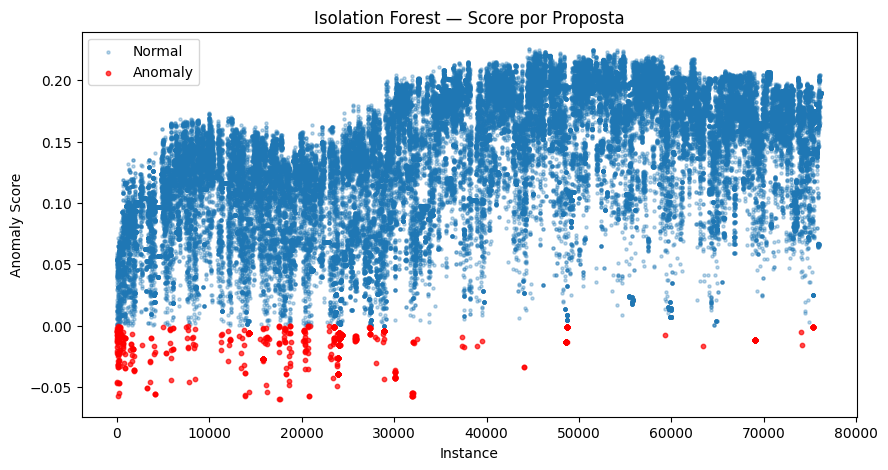

In [34]:
plt.figure(figsize=(10, 5))

normal = df[df['anomaly'] == 1]
plt.scatter(normal.index, normal['anomaly_score'], label='Normal', alpha=0.3, s=5)

anomalies = df[df['anomaly'] == -1]
plt.scatter(anomalies.index, anomalies['anomaly_score'], label='Anomaly', alpha=0.7, s=10, color='red')

plt.xlabel("Instance")
plt.ylabel("Anomaly Score")
plt.title("Isolation Forest — Score por Proposta")
plt.legend()
plt.show()

#### Histograma de distribuição

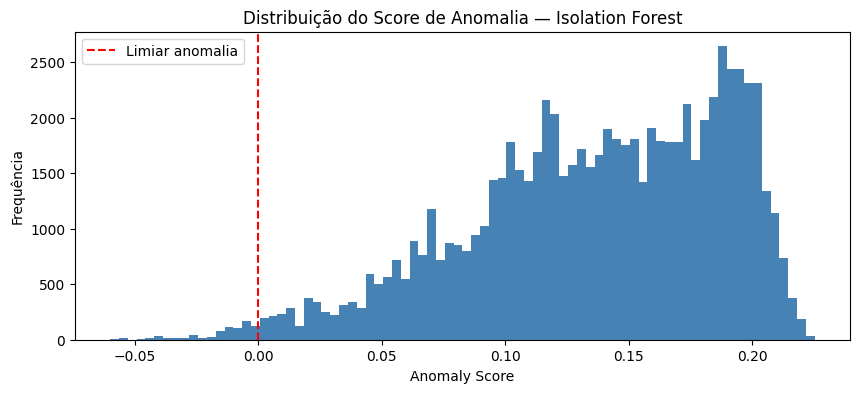

Total de anomalias detectadas: 762 (1.0%)


In [35]:
# Distribuição do anomaly_score
plt.figure(figsize=(10, 4))
plt.hist(df['anomaly_score'], bins=80, color='steelblue', edgecolor='none')
plt.axvline(df[df['anomaly'] == -1]['anomaly_score'].max(), color='red', linestyle='--', label='Limiar anomalia')
plt.xlabel("Anomaly Score")
plt.ylabel("Frequência")
plt.title("Distribuição do Score de Anomalia — Isolation Forest")
plt.legend()
plt.show()

print(f"Total de anomalias detectadas: {(df['anomaly'] == -1).sum()} ({(df['anomaly'] == -1).mean():.1%})")

---
### Local Outlier Factor - LOF

### Resultados e Visualizações - LOF

--- 
### One Class SVM

### Resultados e Visualizações - One Class SVM

---